# Una batería sobre una muestra propia: contrato 1, run_suite y los semáforos

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los cuadernos 01 a 03 de este tema
- **Tiempo de lectura:** unos 40 minutos

## Objetivos

Al terminar este cuaderno puedes:

- pasar un CSV de deudores puntuados por el contrato 1 y leer qué acepta, marca y rechaza, y por qué nunca fuerza un valor;
- asignar las PD a la escala maestra y construir la tabla de grados que leen las pruebas por grado;
- correr una batería de pruebas del motor bajo una sola política con `run_suite`, que nunca se detiene en la primera falla, y leer su tabla de luces;
- explicar por qué las pruebas de nivel y la de estabilidad están en rojo en la muestra actual mientras la de ordenamiento está en verde, y por qué la muestra de desarrollo calibrada está en verde en todas las pruebas de nivel;
- comprobar que la batería de este cuaderno da los mismos números que la puerta del propio pipeline, `data-pipeline/validate.py`.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==0.8.1 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti.

Este cuaderno importa además dos lectores del pipeline del producto: el contrato 1 (`pipeline.io.contract`) y la escala maestra (`pipeline.core.calibration`). El pipeline son scripts, no un paquete, así que el cuaderno pone `data-pipeline/` en la ruta de importación y los importa desde ahí: un solo lector para el pipeline, las pruebas y estos cuadernos, nunca una copia. La celda siguiente lo hace e imprime las versiones.

In [1]:
# Poner el pipeline en la ruta de importación, importar los lectores y el motor, e imprimir las versiones de los paquetes
import importlib.metadata as md
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.core.calibration import GRADES, MASTER_SCALE_UPPER, grade_table
from pipeline.io import contract
from pipeline.io.formats import read_csv_rows

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.8.1
numpy 2.4.6
matplotlib 3.11.2


## Datos

Las mismas dos muestras sintéticas con verdad conocida del cuaderno 03, versionadas en `data/examples/` (propietario: este repositorio; sin licencia de terceros, MIT; generadas desde una semilla por `data-pipeline/pipeline/io/examples.py`):

- `scored_sample_development.csv`: 2.000 deudores al 2024-12-31, PD calibradas por construcción. Hace de **muestra de desarrollo**, la referencia con que se compara un validador.
- `scored_sample_current.csv`: 2.000 deudores al 2025-12-31 de una población más riesgosa cuyos incumplimientos llegan a 1,5 veces la PD. Es la **muestra bajo validación**.

Tu propio modelo entra de la misma manera: un CSV con `id`, `observation_date`, `target` y `pd`, una fila por deudor. La forma es la familia `scored_sample` del contrato 1 (`docs/guides/02_validate-your-own-model.md`).

## Método

### Paso 1: el contrato 1 lee, marca y rechaza; nunca fuerza

El contrato 1 interpreta cada valor según su tipo declarado. Una PD de 1,2, un objetivo `yes` o una segunda fila con el mismo identificador en la misma fecha se **rechaza** con el campo, el valor y lo que se esperaba; un valor extraño pero utilizable se **marca**; una columna que la familia no declara se lista como **ignorada** y nunca se usa. Nada se repara en silencio, porque un valor reparado es un número que el validador no vio. La celda siguiente muestra primero la regla sobre cinco filas escritas en la propia celda, tres de ellas erróneas.

In [2]:
# Cinco filas escritas a mano: dos válidas y tres que el contrato 1 debe rechazar (una PD de 1,2, un objetivo "yes", un identificador repetido)
planted = [
    {"id": "A1", "observation_date": "2025-12-31", "target": "0", "pd": "0.05", "segment": "retail"},
    {"id": "A2", "observation_date": "2025-12-31", "target": "1", "pd": "1.2", "segment": "retail"},
    {"id": "A3", "observation_date": "2025-12-31", "target": "yes", "pd": "0.30", "segment": "retail"},
    {"id": "A1", "observation_date": "2025-12-31", "target": "1", "pd": "0.10", "segment": "retail"},
    {"id": "A5", "observation_date": "2025-12-31", "target": "1", "pd": "0.20", "segment": "retail", "extra": "x"},
]
report = contract.validate("scored_sample", planted)
print("conteos:", report.counts())
print("columnas ignoradas:", report.ignored_columns)
for example in report.examples():
    print(f'{example["kind"]:9s} fila {example["row"]} campo {example["field"]:4s} valor {example["value"]!s:5s} esperado: {example["expected"]} | motivo: {example["reason"]}')

conteos: {'input': 5, 'accepted': 2, 'rejected': 3, 'flagged': 0, 'excluded': 0}
columnas ignoradas: ['extra']
rejected  fila 1 campo pd   valor 1.2   esperado: a finite number in (0, 1) (probability) | motivo: out of range
rejected  fila 2 campo target valor yes   esperado: 0 or 1 | motivo: not 0 or 1
rejected  fila 3 campo id   valor A1    esperado: Each identifier appears once per observation date. | motivo: duplicate of an earlier record


Ahora los dos archivos reales. `read_csv_rows` lee el texto sin interpretarlo, `contract.validate` aplica la familia, y los arreglos que necesita la batería salen solo de los registros **aceptados**.

In [3]:
# Leer ambos archivos por el contrato 1 y quedarse con los registros aceptados como arreglos
samples = {}
# Los nombres con que se muestran las muestras
NOMBRES = {"development": "desarrollo", "current": "actual"}
for name in ("development", "current"):
    rows = read_csv_rows(ROOT / "data" / "examples" / f"scored_sample_{name}.csv")
    checked = contract.validate("scored_sample", rows)
    samples[name] = (np.array([r["pd"] for r in checked.accepted]), np.array([r["target"] for r in checked.accepted]))
    print(f"{NOMBRES[name]:12s} conteos del contrato 1: {checked.counts()}")

pd_dev, y_dev = samples["development"]
pd_cur, y_cur = samples["current"]
print("actual: incumplimientos", int(y_cur.sum()), "| esperados", round(float(pd_cur.sum()), 1))
print("desarrollo: incumplimientos", int(y_dev.sum()), "| esperados", round(float(pd_dev.sum()), 1))

desarrollo   conteos del contrato 1: {'input': 2000, 'accepted': 2000, 'rejected': 0, 'flagged': 0, 'excluded': 0}
actual       conteos del contrato 1: {'input': 2000, 'accepted': 2000, 'rejected': 0, 'flagged': 0, 'excluded': 0}
actual: incumplimientos 207 | esperados 138.1
desarrollo: incumplimientos 100 | esperados 111.2


### Paso 2: la escala maestra y la tabla de grados

Las pruebas de estilo calificación no leen una PD por deudor. Leen **grados**: grupos de deudores con riesgo parecido, cada uno con su conteo, sus incumplimientos y su PD media. Contraste asigna las PD a una escala maestra geométrica (límites superiores 1% por 1,5 elevado a k para k = 0 a 10, y luego 100%: doce grados). La celda siguiente construye la tabla de grados de la muestra actual, descarta los grados vacíos y la imprime.

In [4]:
# Construir la tabla de grados de la muestra actual e imprimir los grados no vacíos
print("grados:", len(GRADES), "| primeras cotas superiores:", [round(b, 4) for b in MASTER_SCALE_UPPER[:4]])
table = [g for g in grade_table(pd_cur, y_cur) if g["n"] > 0]
print(f'{"grado":6s} {"cota":>7s} {"n":>5s} {"incumpl.":>9s} {"PD media":>8s} {"tasa":>7s}')
for g in table:
    print(f'{g["grade"]:6s} {g["hi"]:7.4f} {g["n"]:5d} {g["d"]:9d} {g["pd"]:8.4f} {g["dr"]:7.4f}')

grados: 12 | primeras cotas superiores: [0.01, 0.015, 0.0225, 0.0338]
grado     cota     n  incumpl. PD media    tasa
G01     0.0100   189         1   0.0052  0.0053
G02     0.0150   115         1   0.0125  0.0087
G03     0.0225   155         3   0.0188  0.0194
G04     0.0338   207         6   0.0278  0.0290
G05     0.0506   290        22   0.0419  0.0759
G06     0.0759   352        25   0.0626  0.0710
G07     0.1139   317        48   0.0926  0.1514
G08     0.1709   233        49   0.1388  0.2103
G09     0.2563   121        43   0.2039  0.3554
G10     0.3844    20         9   0.3002  0.4500
G11     0.5767     1         0   0.4619  0.0000


### Paso 3: una batería de pruebas, una política

Una batería es una lista de tareas, cada una un par de una función de prueba y sus argumentos. `run_suite` las corre en orden bajo una política y da a cada `TestResult` el mismo identificador de modelo y segmento. Las tareas siguientes son las que un validador corre sobre un modelo de PD:

| Prueba | Qué pregunta | Referencia |
|---|---|---|
| `disc.auc` | ¿la PD ordena a los incumplidores sobre los no incumplidores? | ECB 2019, Anexo 1 (sección 3.1) |
| `disc.auc_vs_initial` | ¿empeoró el ordenamiento desde el desarrollo (unilateral)? | ECB 2019, sección 2.5.4.1 |
| `pd.jeffreys`, `pd.binomial` | ¿es demasiado baja la PD de la cartera? | ECB 2019; BCBS WP14 |
| `pd.binomial_vasicek` | lo mismo, admitiendo una correlación de incumplimiento de un factor (rho = 0,04, el valor de Basilea para minorista renovable) | BCBS WP14 |
| `pd.chi2_grades` | ¿los incumplimientos de todos los grados coinciden con sus PD? | BCBS WP14 |
| `pd.hosmer_lemeshow`, `pd.spiegelhalter` | ¿las PD a nivel de deudor coinciden con los resultados? | Hosmer y Lemeshow 1980; Spiegelhalter 1986 |
| `stability.psi` | ¿se movió la distribución de la PD desde el desarrollo, frente al criterio chi-cuadrado? | Yurdakul y Naranjo 2020 |

Las pruebas que comparan con el desarrollo lo necesitan como referencia: el AUC en el desarrollo (con su varianza) y los diez tramos por cuantiles de las PD de desarrollo para el PSI. La celda siguiente define una función pequeña que lista las tareas de una muestra y una referencia opcional. La función elige qué pruebas del motor llamar y con qué arreglos; cada estadístico lo calcula el motor.

In [5]:
# Listar las tareas del motor para una muestra; el motor calcula cada estadístico, esta función solo elige las llamadas
from riskvalidation.validation import calibration as cal
from riskvalidation.validation import discrimination as disc
from riskvalidation.validation import stability as st

RETAIL_REVOLVING_RHO = 0.04


def battery_tasks(pd_eval, y_eval, reference=None):
    # Los insumos de las pruebas de nivel: los grados no vacíos de la escala maestra y los totales de la cartera
    grades = [g for g in grade_table(pd_eval, y_eval) if g["n"] > 0]
    n_obligors, n_defaults, mean_pd = len(y_eval), int(y_eval.sum()), float(pd_eval.mean())
    # La prueba de ordenamiento solo necesita la muestra
    tasks = [(disc.disc_auc, dict(risk=pd_eval, defaults=y_eval))]
    # Con referencia: el AUC frente al desarrollo lleva la varianza propia del AUC de desarrollo
    if reference is not None:
        pd_ref, y_ref = reference
        auc_ref, variance_ref, *_ = disc.auc_with_variance(pd_ref, y_ref)
        tasks.append((disc.disc_auc_vs_initial, dict(auc_initial=float(auc_ref), risk=pd_eval, defaults=y_eval, auc_initial_variance=float(variance_ref))))
    # Las pruebas de nivel y de ajuste solo necesitan la muestra
    tasks += [
        (cal.pd_jeffreys, dict(n=n_obligors, d=n_defaults, pd=mean_pd)),
        (cal.pd_binomial, dict(n=n_obligors, d=n_defaults, pd=mean_pd)),
        (cal.pd_binomial_vasicek, dict(n=n_obligors, d=n_defaults, pd=mean_pd, rho=RETAIL_REVOLVING_RHO)),
        (cal.pd_chi2_grades, dict(n=[g["n"] for g in grades], d=[g["d"] for g in grades], pd=[g["pd"] for g in grades])),
        (cal.pd_hosmer_lemeshow, dict(defaults=y_eval, pd=pd_eval, fitted=False)),
        (cal.pd_spiegelhalter, dict(defaults=y_eval, pd=pd_eval)),
    ]
    # Con referencia: los tramos del PSI son los deciles de las PD de desarrollo, fijados antes de ver la muestra actual
    if reference is not None:
        edges = st.quantile_edges(pd_ref, 10)
        tasks.append((st.stability_psi, dict(expected_counts=st.bin_counts(pd_ref, edges), actual_counts=st.bin_counts(pd_eval, edges))))
    return tasks


current_tasks = battery_tasks(pd_cur, y_cur, reference=(pd_dev, y_dev))
print("tareas:", [func.__name__ for func, _ in current_tasks])

tareas: ['disc_auc', 'disc_auc_vs_initial', 'pd_jeffreys', 'pd_binomial', 'pd_binomial_vasicek', 'pd_chi2_grades', 'pd_hosmer_lemeshow', 'pd_spiegelhalter', 'stability_psi']


Dos elecciones merecen un comentario. `fitted=False` le dice a Hosmer-Lemeshow que las PD no se ajustaron con esta muestra, por lo que usa tantos grados de libertad como grupos (un modelo ajustado usaría dos menos). Y el AUC frente al desarrollo es una prueba unilateral (rechaza solo cuando el AUC bajó), y lleva la varianza propia del AUC de desarrollo: ignorarla hace que la prueba rechace más a menudo que su nivel nominal cuando nada cambió.

Ahora la corrida. `run_suite` recibe las tareas, la política y los identificadores.

In [6]:
# Correr la batería bajo la política por defecto y leer los conteos y la peor luz
from riskvalidation import run_suite

policy = rv.default_policy()
suite = run_suite(current_tasks, policy=policy, model_id="own-model", segment="portfolio")
print("política:", suite.policy_version)
print("resultados:", len(suite.results))
print("conteos:", suite.counts())
print("peor luz:", suite.worst().value)

política: riskvalidation-default 2026.10.1
resultados: 9
conteos: {'green': 2, 'amber': 0, 'red': 6, 'not_evaluated': 1, 'error': 0}
peor luz: red


### Paso 4: leer la tabla de luces

Una fila por prueba, con su valor p, su métrica (cuando la tiene) y la luz. La celda siguiente la imprime en el orden de la batería.

In [7]:
# Imprimir la tabla de luces: valor p, métrica y luz
def lights_table(run):
    print(f"{'prueba':22s} {'valor p':>12s} {'métrica':>10s}  luz")
    for result in run.results:
        p_text = "-" if result.p_value is None else format(result.p_value, ".4g")
        m_text = "-" if result.metric is None else format(result.metric, ".4f")
        print(f"{result.test_id:22s} {p_text:>12s} {m_text:>10s}  {result.light.value}")


lights_table(suite)

prueba                      valor p    métrica  luz
disc.auc                          -     0.7791  not_evaluated
disc.auc_vs_initial          0.9142          -  green
pd.jeffreys               6.047e-09          -  red
pd.binomial               7.591e-09          -  red
pd.binomial_vasicek          0.1139          -  green
pd.chi2_grades            2.648e-07          -  red
pd.hosmer_lemeshow        3.872e-09          -  red
pd.spiegelhalter          3.645e-09          -  red
stability.psi             4.211e-10     0.0626  red


### Paso 5: el PSI, abierto

El PSI compara la proporción de cada muestra en $B$ tramos fijados con la muestra de desarrollo. Con $E_i$ y $A_i$ los conteos de la muestra de desarrollo y de la actual en el tramo $i$, $n = \sum_i E_i$, $m = \sum_i A_i$, $e_i = E_i / n$ y $a_i = A_i / m$:

$$\mathrm{PSI} = \sum_{i=1}^{B} (a_i - e_i)\,\ln\frac{a_i}{e_i}$$

Un tramo vacío se fija en media observación de su muestra, de modo que el logaritmo sigue siendo finito. La lectura habitual del PSI es una regla práctica (0,10 y 0,25) usada sin referencia a tasas de error. Yurdakul y Naranjo (2020, doi:10.21314/JRMV.2020.227) muestran que, escalado por los dos tamaños de muestra, el PSI sigue una distribución chi-cuadrado con $B - 1$ grados de libertad cuando nada cambió:

$$\left(\frac{1}{n} + \frac{1}{m}\right)^{-1}\mathrm{PSI} \;\approx\; \chi^2_{B-1}$$

lo que da un valor p (la cola superior) y un PSI crítico al nivel $\alpha$:

$$\mathrm{PSI}_{\mathrm{crit}} = \left(\frac{1}{n} + \frac{1}{m}\right)\chi^2_{1-\alpha,\,B-1}$$

La luz del motor sigue ese valor p. Los diez tramos son los deciles de las PD de desarrollo, así que la muestra de desarrollo tiene 200 deudores en cada uno. La celda siguiente cuenta la muestra actual en los mismos tramos.

In [8]:
# Los diez tramos son los deciles de las PD de desarrollo; contar cuántos deudores de cada muestra caen en cada tramo
edges = st.quantile_edges(pd_dev, 10)
expected_counts = st.bin_counts(pd_dev, edges)
actual_counts = st.bin_counts(pd_cur, edges)
print("conteos de desarrollo por tramo:", expected_counts.tolist())
print("conteos actuales por tramo:     ", actual_counts.tolist())

conteos de desarrollo por tramo: [200, 200, 200, 200, 200, 200, 200, 200, 200, 200]
conteos actuales por tramo:      [136, 176, 152, 168, 200, 202, 190, 217, 218, 341]


El resultado del motor lleva de qué está hecho el estadístico. La celda siguiente lo lee de la fila del PSI de la batería: el PSI y su contribución por tramo, la escala $1/n + 1/m$, el estadístico escalado, su valor p y el PSI crítico al 5%.

In [9]:
# La fila del PSI de la batería: el estadístico, su escala, el estadístico escalado, el valor p y el PSI crítico al 5%
psi = next(r for r in suite.results if r.test_id == "stability.psi")
n_dev, n_cur = psi.extras["n"], psi.extras["m"]
scale = 1 / n_dev + 1 / n_cur
print("PSI:", round(psi.metric, 6), "| tramos:", psi.extras["bins"])
print("contribución por tramo:", [round(c, 4) for c in psi.extras["contributions"]])
print("escala 1/n + 1/m:", scale)
print("estadístico escalado PSI / escala:", round(psi.metric / scale, 3), "| grados de libertad:", psi.extras["bins"] - 1)
print("valor p:", format(psi.p_value, ".4g"))
print("PSI crítico al 5%:", round(psi.extras["benchmark_05"], 4), "| banda convencional:", psi.extras["band"])

PSI: 0.062603 | tramos: 10
contribución por tramo: [0.0123, 0.0015, 0.0066, 0.0028, 0.0, 0.0, 0.0003, 0.0007, 0.0008, 0.0376]
escala 1/n + 1/m: 0.001
estadístico escalado PSI / escala: 62.603 | grados de libertad: 9
valor p: 4.211e-10
PSI crítico al 5%: 0.0169 | banda convencional: little change


### Paso 6: Hosmer-Lemeshow, abierto

La prueba de Hosmer-Lemeshow (Hosmer y Lemeshow, 1980) ordena a los deudores por PD, los corta en $G$ grupos de igual tamaño y compara, en cada grupo $g$, los incumplimientos observados $O_g$ con los esperados $E_g$ (la suma de las PD de sus $m_g$ deudores):

$$\mathrm{HL} = \sum_{g=1}^{G} \frac{(O_g - E_g)^2}{E_g\,(1 - E_g / m_g)}$$

La distribución de referencia es chi-cuadrado, y sus grados de libertad dependen del origen de las PD:

$$\mathrm{HL} \sim \chi^2_{G} \quad \text{(PD dadas antes de los resultados)}, \qquad \mathrm{HL} \sim \chi^2_{G-2} \quad \text{(PD ajustadas con estas mismas observaciones)}$$

Una muestra de validación es el primer caso, por eso la batería fija `fitted=False` y el motor usa $G = 10$ grados de libertad. La celda siguiente lee el estadístico de la batería.

In [10]:
# Hosmer-Lemeshow sobre la muestra actual: el estadístico, los grupos y los grados de libertad que usó el motor
hl = next(r for r in suite.results if r.test_id == "pd.hosmer_lemeshow")
print("estadístico HL:", round(hl.statistic, 3), "| grupos:", hl.extras["groups"])
print("grados de libertad:", hl.extras["dof"], "| fitted:", hl.extras["fitted"])
print("valor p:", format(hl.p_value, ".4g"))

estadístico HL: 59.848 | grupos: 10
grados de libertad: 10 | fitted: False
valor p: 3.872e-09


El mismo estadístico bajo la otra regla: si las PD se hubieran ajustado con esta misma muestra, el motor usaría $G - 2 = 8$ grados de libertad y daría otro valor p. La celda siguiente muestra cuánto importa la regla.

In [11]:
# El mismo estadístico leído bajo la otra regla: las PD ajustadas con esta misma muestra pierden dos grados de libertad
hl_fitted = cal.pd_hosmer_lemeshow(defaults=y_cur, pd=pd_cur, fitted=True, policy=policy, model_id="own-model", segment="portfolio")
print("fitted=True | grados de libertad:", hl_fitted.extras["dof"], "| valor p:", format(hl_fitted.p_value, ".4g"), "| luz:", hl_fitted.light.value)

fitted=True | grados de libertad: 8 | valor p: 4.991e-10 | luz: red


### Paso 7: la chi-cuadrado por grados, abierta

La prueba por grados (BCBS Working Paper 14) toma los $K$ grados no vacíos de la escala maestra, con $n_i$ deudores, $d_i$ incumplimientos y PD media $p_i$ en el grado $i$:

$$T = \sum_{i=1}^{K} \frac{(n_i p_i - d_i)^2}{n_i\,p_i\,(1 - p_i)} \;\sim\; \chi^2_{K}$$

Los grados de libertad son el número de grados, no ese número menos una cuenta de ajuste, porque las PD de una escala maestra son dadas. El motor advierte que la prueba probablemente subestima el error de tipo I bajo dependencia entre incumplimientos. La celda siguiente lee el estadístico y los grados de libertad de la batería.

In [12]:
# La chi-cuadrado por grados de la batería: el estadístico, el número de grados que cuenta y el valor p
chi = next(r for r in suite.results if r.test_id == "pd.chi2_grades")
print("T:", round(chi.statistic, 3), "| grados contados (no vacíos):", chi.extras["dof"])
print("grados de libertad:", chi.extras["dof"], "| valor p:", format(chi.p_value, ".4g"))

T: 52.07 | grados contados (no vacíos): 11
grados de libertad: 11 | valor p: 2.648e-07


### Paso 8: la muestra calibrada, sola

Una batería solo convence si deja en paz a un modelo correcto. La muestra de desarrollo está calibrada por construcción. Las pruebas de nivel no necesitan una referencia, así que corremos las tareas sin ella: ni AUC frente al inicial ni PSI, que compararían una muestra consigo misma.

In [13]:
# Correr las pruebas de nivel y de ajuste sobre la muestra de desarrollo sola
alone = run_suite(battery_tasks(pd_dev, y_dev), policy=policy, model_id="own-model", segment="portfolio")
lights_table(alone)
print("conteos:", alone.counts())

prueba                      valor p    métrica  luz
disc.auc                          -     0.7426  not_evaluated
pd.jeffreys                  0.8629          -  green
pd.binomial                  0.8737          -  green
pd.binomial_vasicek          0.5401          -  green
pd.chi2_grades               0.5088          -  green
pd.hosmer_lemeshow           0.6875          -  green
pd.spiegelhalter             0.8311          -  green
conteos: {'green': 6, 'amber': 0, 'red': 0, 'not_evaluated': 1, 'error': 0}


### Paso 9: una batería nunca se detiene en la primera falla

Un validador necesita el panorama completo, por lo que una prueba que lanza una excepción se registra como un resultado `error` con el texto de la excepción, y las pruebas restantes siguen corriendo. La celda siguiente agrega una tarea que debe fallar (la prueba de Jeffreys sobre una cartera de cero deudores) en medio de la batería.

In [14]:
# Insertar una tarea que debe fallar y mostrar que la batería la registra y termina
broken = [current_tasks[0], (cal.pd_jeffreys, dict(n=0, d=0, pd=0.05)), current_tasks[3]]
mixed = run_suite(broken, policy=policy, model_id="own-model", segment="portfolio")
for result in mixed.results:
    print(f"{result.test_id:14s} {result.light.value:14s} {result.notes}")
print("conteos:", mixed.counts(), "| peor:", mixed.worst().value)

disc.auc       not_evaluated  policy riskvalidation-default 2026.10.1 holds no thresholds for this test; no light assigned
pd.jeffreys    error          ValueError: the Jeffreys test needs at least one obligor
pd.binomial    red            assumes independent defaults; WP14: the true type I error can be much larger if defaults are correlated
conteos: {'green': 0, 'amber': 0, 'red': 1, 'not_evaluated': 1, 'error': 1} | peor: error


### Paso 10: los mismos números que la puerta del producto

`data-pipeline/validate.py` es la puerta de línea de comandos para tu propio modelo. Corre la batería completa del pipeline sobre un CSV con las mismas llamadas al motor. La celda siguiente llama a su función sobre los mismos dos archivos y comprueba que cada prueba de la batería anterior tenga allí el mismo valor p o la misma métrica y la misma luz.

In [15]:
# Comparar la batería anterior con el informe de la puerta del propio pipeline sobre los mismos archivos (no se escribe nada)
from pipeline.own_sample import validate_own

examples = ROOT / "data" / "examples"
door = validate_own(examples / "scored_sample_current.csv", reference=examples / "scored_sample_development.csv", model_id="own-model")
door_rows = {(row["test_id"], row["segment"]): row for row in door["tests"]}

agree = []
for result in suite.results:
    row = door_rows[(result.test_id, "portfolio")]
    same_value = np.isclose(row["p_value"] if result.p_value is not None else row["metric"], result.p_value if result.p_value is not None else result.metric)
    agree.append(bool(same_value and row["light"] == result.light.value))
print("pruebas comparadas:", len(agree), "| todas coinciden:", all(agree))
print("pruebas en la batería completa de la puerta:", len(door["tests"]), "| luces:", door["lights"])

pruebas comparadas: 9 | todas coinciden: True
pruebas en la batería completa de la puerta: 24 | luces: {'green': 10, 'not_evaluated': 4, 'red': 10}


### Paso 11: la evidencia, dibujada

La última celda dibuja lo que vieron las pruebas de nivel. Para cada grado de la escala maestra, los incumplimientos que esperan las PD (la suma de las PD) y los observados, con la muestra de desarrollo a la izquierda y la actual a la derecha.

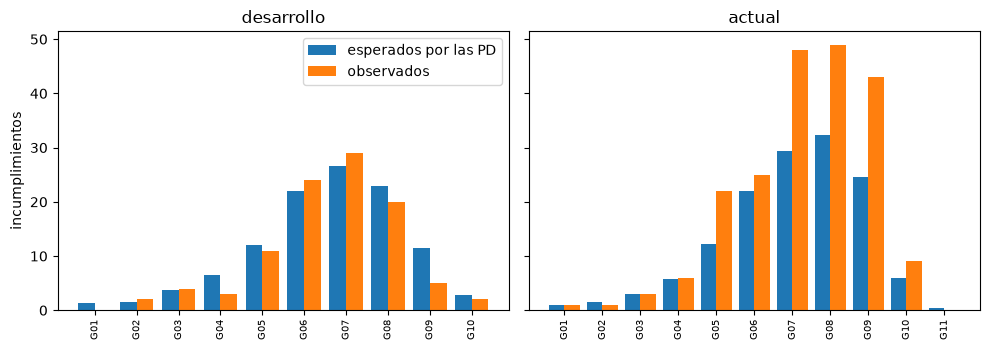

In [16]:
# Dibujar los incumplimientos esperados y observados por grado para las dos muestras
LABELS = ("esperados por las PD", "observados")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, (name, (pd_s, y_s)) in zip(axes, samples.items()):
    grades = [g for g in grade_table(pd_s, y_s) if g["n"] > 0]
    positions = np.arange(len(grades))
    expected = [g["pd"] * g["n"] for g in grades]
    ax.bar(positions - 0.2, expected, width=0.4, label=LABELS[0])
    ax.bar(positions + 0.2, [g["d"] for g in grades], width=0.4, label=LABELS[1])
    ax.set_xticks(positions)
    ax.set_xticklabels([g["grade"] for g in grades], rotation=90, fontsize=7)
    ax.set_title(NOMBRES[name])
axes[0].set_ylabel("incumplimientos")
axes[0].legend()
fig.tight_layout()
plt.show()

## Resultados

- **El contrato 1 rechazó exactamente lo que debía.** De las cinco filas escritas a mano rechazó la PD de 1,2, el objetivo `yes` y el identificador repetido, aceptó las otras dos y listó la columna adicional como ignorada. Los dos archivos reales se aceptaron completos.
- **La muestra actual es encontrada.** Seis de las ocho pruebas que tienen umbral están en rojo: la de Jeffreys, la binomial, la chi-cuadrado por grados, Hosmer-Lemeshow, Spiegelhalter y el PSI. La causa se ve en la figura: del grado G05 al G10 los incumplimientos observados superan lo que esperan las PD, con el patrón de un nivel demasiado bajo. La verdad, incumplimientos a 1,5 veces la PD, es lo que encuentran las pruebas.
- **El ordenamiento se mantiene.** El AUC de la muestra actual (cerca de 0,78) no es menor que el de la muestra de desarrollo sola (cerca de 0,74), y la prueba del AUC frente al inicial es verde. Un modelo puede ordenar tan bien como en el desarrollo y tener mal el tamaño: por eso la batería tiene pruebas de nivel además de pruebas de discriminación.
- **La binomial con ajuste de Vasicek es verde.** Con una correlación de activos de 0,04, el exceso de incumplimientos de un período es compatible con un choque sistemático, y un solo período no puede distinguir ambos. Las pruebas que suponen independencia son las más sensibles y las más propensas a equivocarse en el otro sentido. Aquí la verdad son incumplimientos independientes a 1,5 veces la PD, así que el verde de Vasicek es una detección perdida: el precio de admitir correlación es la potencia. Cada llamada al motor devuelve una prueba, así que la batería corre ambas para mostrar el contraste.
- **El PSI es rojo aunque su valor, 0,063, está dentro de la banda convencional de 0,10.** La política lee el PSI frente al criterio chi-cuadrado de Yurdakul y Naranjo, que con 2.000 deudores por muestra detecta un cambio que la regla práctica no ve (el PSI crítico al 5% es 0,0169, paso 5).
- **La muestra calibrada queda en paz.** Toda prueba de nivel es verde en la muestra de desarrollo.
- **La puerta coincide.** La función propia del pipeline devuelve los mismos valores p, métricas y luces que la batería construida en este cuaderno.

Lo que las luces no muestran: son la lectura de la política por defecto, no un veredicto de cumplimiento (cuaderno 03), y las muestras son sintéticas con verdad conocida, algo que las carteras reales nunca tienen.

## Resumen

- El contrato 1 convierte un CSV en registros aceptados e informa lo que rechazó, marcó o ignoró; nunca fuerza un valor.
- La escala maestra convierte las PD en grados, y la tabla de grados es el insumo de las pruebas por grado.
- `run_suite` corre una lista de tareas `(función, argumentos)` bajo una política, registra una prueba que falla como un resultado `error` y termina la batería.
- Las pruebas de nivel encuentran la muestra desplazada y dejan en paz a la calibrada; la prueba de ordenamiento no basta por sí sola; el PSI se lee frente a un criterio, no a una regla práctica.
- La batería del cuaderno y la puerta del producto dan los mismos números, porque ambas llaman al mismo motor.

**Qué probar a continuación.** Pasa tu propia muestra puntuada por la puerta (`data-pipeline/validate.py`, ver `docs/guides/02_validate-your-own-model.md`) y compara su tabla con esta. Luego lee `docs/guides/03_read-a-validation-report.md` y sigue con el tema 02, que construye los modelos que valida esta batería.

## Referencias

- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk, secciones 2.5.3.1 y 2.5.4.1 y Anexo 1 (sección 3.1). https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- BCBS (2005), Studies on the validation of internal rating systems, Working Paper 14 (revised): la binomial, la binomial con ajuste de Vasicek y la chi-cuadrado por grados. https://www.bis.org/publications/studies-validation-internal-rating-systems-revised.pdf
- Yurdakul, B. y Naranjo, J. (2020), Statistical properties of the population stability index, Journal of Risk Model Validation 14(4). https://doi.org/10.21314/JRMV.2020.227
- Hosmer, D. W. y Lemeshow, S. (1980), Goodness of fit tests for the multiple logistic regression model, Communications in Statistics, Theory and Methods 9(10). https://doi.org/10.1080/03610928008827941
- Spiegelhalter, D. J. (1986), Probabilistic prediction in patient management and clinical trials, Statistics in Medicine 5(5). https://doi.org/10.1002/sim.4780050506
- Este repositorio: `docs/guides/02_validate-your-own-model.md` y `docs/guides/03_read-a-validation-report.md`.